# MLGuard: Dataset and Model Audit Copilot




In [1]:
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from pandas.api.types import is_numeric_dtype, is_integer_dtype

warnings.filterwarnings("ignore")  
sns.set_theme(style="whitegrid")

In [2]:
def load_data(name):
    """Return (dataframe, target_column) for a dataset name."""
    if name == "titanic":
        return sns.load_dataset("titanic"), "survived"      

    if name == "telco":
       
        for path in ["../data/telco_churn.csv", "data/telco_churn.csv", "telco_churn.csv"]:
            try:
                return pd.read_csv(path), "Churn"
            except FileNotFoundError:
                continue
        raise FileNotFoundError("telco_churn.csv not found. Put it in the data folder.")

    if name == "diabetes":
        return load_diabetes(as_frame=True).frame, "target"  

    raise ValueError("Unknown dataset: " + name)

In [3]:
datasets = {name: load_data(name) for name in ["titanic", "telco", "diabetes"]}

for name, (data, target) in datasets.items():
    print(f"{name:9s} rows={data.shape[0]:5d}  columns={data.shape[1]:3d}  target={target}")

titanic   rows=  891  columns= 15  target=survived
telco     rows= 7043  columns= 21  target=Churn
diabetes  rows=  442  columns= 11  target=target


##  Detecting the Task (Classification or Regression)




In [4]:
def detect_task(data, target_col):
    
    s = data[target_col]

   
    if not is_numeric_dtype(s):
        return "Classification"
    if s.nunique() < 15:
        return "Classification"
    return "Regression"

for name, (data, target) in datasets.items():
    print(name, "->", detect_task(data, target))

titanic -> Classification
telco -> Classification
diabetes -> Regression


##  Data Quality Check


In [5]:
def audit_quality(df):
    """Check missing values, duplicates, constant columns and wrong data types."""
    data = df.copy()                       # work on a copy, never on the original
    report = {}
    n_rows = len(data)

    # 1. Missing values (count and percent)
    missing = data.isnull().sum()
    missing = missing[missing > 0]
    report["missing"] = missing.to_dict()
    report["missing_percent"] = (missing / n_rows * 100).round(2).to_dict()

    # 2. Duplicate rows
    report["duplicates"] = int(data.duplicated().sum())

    # 3. Constant columns: only one unique value
    report["constant_cols"] = [c for c in data.columns if data[c].nunique() <= 1]

    # 4. Wrong data types: text column where more than 80% values can become numbers
    wrong = []
    for col in data.columns:
        if not is_numeric_dtype(data[col]):
            converted = pd.to_numeric(data[col], errors="coerce")   # bad values become NaN
            original_count = data[col].notnull().sum()
            if original_count > 0 and converted.notnull().sum() / original_count > 0.8:
                wrong.append(col)
    report["wrong_dtypes"] = wrong

    return report

Outlier Check (IQR Method)


In [6]:
def check_outliers(df, target_col):
    """Count outliers in each numeric feature using the IQR rule."""
    result = {}
    for col in df.select_dtypes(include="number").columns:
        if col == target_col:
            continue
        s = df[col].dropna()

        if s.nunique() <= 2:               # skip 0/1 columns, outliers make no sense there
            continue

        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        if iqr == 0:
            continue

        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((s < lower) | (s > upper)).sum())
        if n_out > 0:
            result[col] = {"count": n_out, "percent": round(n_out / len(s) * 100, 2)}
    return result

##  Class Imbalance Check


In [7]:
def check_imbalance(df, target_col, task):
    """For classification: check how small the smallest class is."""
    if task != "Classification":
        return {"applicable": False}

    percent = (df[target_col].value_counts(normalize=True) * 100).round(2)
    minority = float(percent.min())

    if minority < 10:
        severity = "High"
    elif minority < 30:
        severity = "Medium"
    else:
        severity = "Low"

    return {"applicable": True, "class_percent": percent.to_dict(),
            "minority_percent": minority, "severity": severity}

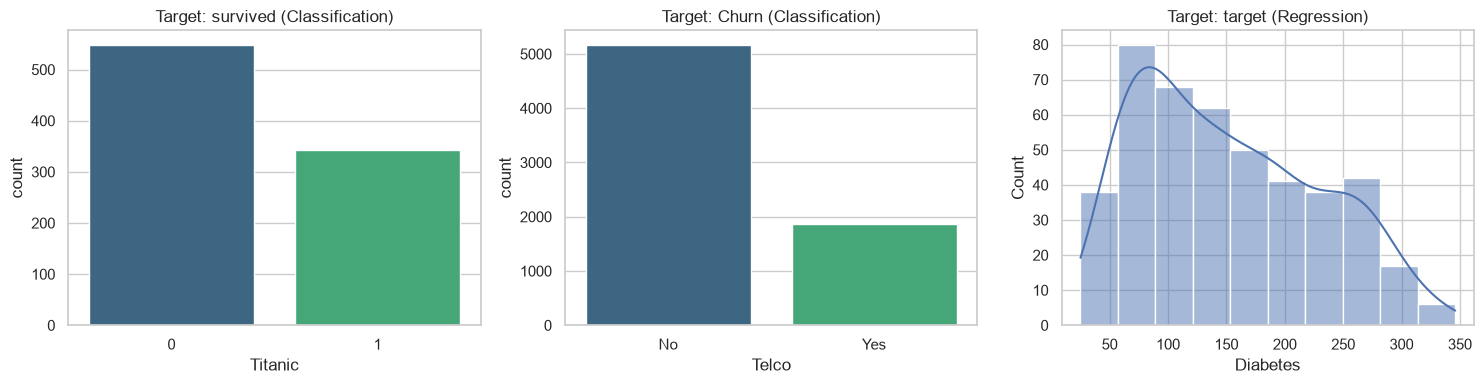

In [8]:
def plot_target(df, target_col, task, ax=None):
    """Draw the target distribution."""
    if ax is None:
        ax = plt.gca()
    if task == "Classification":
        sns.countplot(data=df, x=target_col, hue=target_col, palette="viridis", legend=False, ax=ax)
    else:
        sns.histplot(df[target_col], kde=True, ax=ax)
    ax.set_title(f"Target: {target_col} ({task})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (data, target)) in zip(axes, datasets.items()):
    plot_target(data, target, detect_task(data, target), ax=ax)
    ax.set_xlabel(name.capitalize())
plt.tight_layout()
plt.show()

In [9]:
def detect_basic_leakage(df, target_col):
    """Find ID-like columns and features very highly correlated with the target."""
    data = df.copy()

    # 1. ID-like columns: integer or text, and every row is unique
    id_cols = []
    for col in data.columns:
        if col == target_col:
            continue
        s = data[col]
        is_int_or_text = is_integer_dtype(s) or (not is_numeric_dtype(s))
        if is_int_or_text and s.nunique() == len(data):
            id_cols.append(col)

    # 2. Correlation: turn a text target (Yes/No) into numbers 0/1, only for this check
    if not is_numeric_dtype(data[target_col]):
        data[target_col] = pd.factorize(data[target_col])[0]

    num_cols = data.select_dtypes(include="number").columns
    high_corr = []
    if target_col in num_cols:
        corr = data[num_cols].corr()[target_col].drop(target_col)
        high_corr = [c for c, v in corr.items() if abs(v) > 0.9]   # 0.9 = suspicious level

    return {"id_columns": id_cols, "highly_correlated": high_corr}


The same functions run on every dataset. This shows that MLGuard is **dynamic**.

In [10]:
for name, (data, target) in datasets.items():
    task = detect_task(data, target)
    print("=" * 60)
    print(name.upper(), "| task:", task)
    print("QUALITY   :", audit_quality(data))
    print("OUTLIERS  :", check_outliers(data, target))
    print("IMBALANCE :", check_imbalance(data, target, task))
    print("LEAKAGE   :", detect_basic_leakage(data, target))

TITANIC | task: Classification
QUALITY   : {'missing': {'age': 177, 'embarked': 2, 'deck': 688, 'embark_town': 2}, 'missing_percent': {'age': 19.87, 'embarked': 0.22, 'deck': 77.22, 'embark_town': 0.22}, 'duplicates': 107, 'constant_cols': [], 'wrong_dtypes': []}
OUTLIERS  : {'age': {'count': 11, 'percent': 1.54}, 'sibsp': {'count': 46, 'percent': 5.16}, 'fare': {'count': 116, 'percent': 13.02}}
IMBALANCE : {'applicable': True, 'class_percent': {0: 61.62, 1: 38.38}, 'minority_percent': 38.38, 'severity': 'Low'}
LEAKAGE   : {'id_columns': [], 'highly_correlated': []}
TELCO | task: Classification
QUALITY   : {'missing': {}, 'missing_percent': {}, 'duplicates': 0, 'constant_cols': [], 'wrong_dtypes': ['TotalCharges']}
OUTLIERS  : {}
IMBALANCE : {'applicable': True, 'class_percent': {'No': 73.46, 'Yes': 26.54}, 'minority_percent': 26.54, 'severity': 'Medium'}
LEAKAGE   : {'id_columns': ['customerID'], 'highly_correlated': []}
DIABETES | task: Regression
QUALITY   : {'missing': {}, 'missing

In [11]:
# New imports for Day 2 (you can also paste these into your first import cell)
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (balanced_accuracy_score, accuracy_score, precision_score,
                             recall_score, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score)

In [12]:
def convert_numeric_text(df):
    """Text columns that really hold numbers (like Telco TotalCharges) become numeric.
    Works on a copy. The user's original data is not changed."""
    data = df.copy()
    for col in data.columns:
        if not is_numeric_dtype(data[col]):
            converted = pd.to_numeric(data[col], errors="coerce")
            original_count = data[col].notnull().sum()
            if original_count > 0 and converted.notnull().sum() / original_count > 0.8:
                data[col] = converted
    return data

In [13]:
def prepare_features(df, target_col, exclude_cols=()):
    """Turn a dataframe into numbers only, so scikit-learn can use it."""
    data = convert_numeric_text(df).dropna(subset=[target_col])   # rows without a target are useless
    y = data[target_col]
    if not is_numeric_dtype(y):
        y = pd.Series(pd.factorize(y)[0], index=y.index)   # Yes/No -> 1/0

    X = data.drop(columns=[target_col] + list(exclude_cols))
    categorical = []
    for col in X.columns:
        if is_numeric_dtype(X[col]):
            X[col] = X[col].astype(float)
            X[col] = X[col].fillna(X[col].median())    # fill empty cells with the median
        else:
            X[col] = pd.factorize(X[col])[0]           # text -> number codes (missing = -1)
            categorical.append(col)
    return X, y, categorical

In [14]:
def mutual_info_table(df, target_col, task, exclude_cols=()):
    """Rank features by mutual information with the target."""
    X, y, categorical = prepare_features(df, target_col, exclude_cols)
    is_discrete = [c in categorical for c in X.columns]   # tell sklearn which are categories

    if task == "Classification":
        mi = mutual_info_classif(X, y, discrete_features=is_discrete, random_state=42)
    else:
        mi = mutual_info_regression(X, y, discrete_features=is_discrete, random_state=42)

    table = pd.DataFrame({"feature": X.columns, "mutual_info": mi.round(4)})

    if task == "Classification":
        # ratio_to_max = 1.0 means this feature explains the whole target (very suspicious)
        p = y.value_counts(normalize=True)
        entropy = float(-(p * np.log(p)).sum())
        table["ratio_to_max"] = (table["mutual_info"] / entropy).round(3)

    return table.sort_values("mutual_info", ascending=False).reset_index(drop=True)

In [15]:
def single_feature_test(df, target_col, task, exclude_cols=(), threshold=0.95):
    """Train a small model on ONE column at a time. A near-perfect score = suspicious."""
    X, y, _ = prepare_features(df, target_col, exclude_cols)
    stratify = y if task == "Classification" else None    # keep the class ratio same in both parts
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=stratify)

    rows = []
    for col in X.columns:
        if task == "Classification":
            model = DecisionTreeClassifier(max_depth=5, random_state=42)
            model.fit(X_train[[col]], y_train)
            score = balanced_accuracy_score(y_test, model.predict(X_test[[col]]))
        else:
            model = DecisionTreeRegressor(max_depth=5, random_state=42)
            model.fit(X_train[[col]], y_train)
            score = r2_score(y_test, model.predict(X_test[[col]]))
        rows.append({"feature": col, "score": round(float(score), 3),
                     "suspicious": score >= threshold})

    return pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)

In [16]:
def detect_leakage(df, target_col, task):
    """Run all leakage checks and give a reason for every suspicious column."""
    df = convert_numeric_text(df)                      # fix numbers stored as text first
    basic = detect_basic_leakage(df, target_col)       # Day 1 function
    id_cols = basic["id_columns"]

    # Text columns with too many different values (more than half of the rows) make
    # mutual information give fake high numbers, so we skip them in the model checks
    many_values = [c for c in df.columns
                   if c != target_col and not is_numeric_dtype(df[c])
                   and df[c].nunique() > 0.5 * len(df) and c not in id_cols]
    skip = id_cols + many_values

    mi = mutual_info_table(df, target_col, task, exclude_cols=skip)
    single = single_feature_test(df, target_col, task, exclude_cols=skip)

    reasons = {}
    def add(col, why):
        reasons.setdefault(col, []).append(why)

    for c in id_cols:
        add(c, "ID-like column (every row is unique)")
    for c in basic["highly_correlated"]:
        add(c, "correlation with target above 0.9")
    for c in single[single["suspicious"]]["feature"]:
        add(c, "alone predicts the target almost perfectly")
    if task == "Classification":
        for c in mi[mi["ratio_to_max"] >= 0.9]["feature"]:
            add(c, "carries 90%+ of the target information")

    return {"suspicious_columns": reasons, "mutual_info": mi, "single_feature": single}

In [17]:
# Test on all 3 datasets
for name, (data, target) in datasets.items():
    task = detect_task(data, target)
    result = detect_leakage(data, target, task)
    print("=" * 60)
    print(name.upper(), "| suspicious columns:", result["suspicious_columns"])
    print("\nTop 5 by mutual information:")
    print(result["mutual_info"].head(5))
    print("\nTop 5 by single-feature score:")
    print(result["single_feature"].head(5))

TITANIC | suspicious columns: {'alive': ['alone predicts the target almost perfectly', 'carries 90%+ of the target information']}

Top 5 by mutual information:
      feature  mutual_info  ratio_to_max
0       alive       0.6659         1.000
1         who       0.1652         0.248
2         sex       0.1509         0.227
3  adult_male       0.1389         0.209
4        fare       0.1225         0.184

Top 5 by single-feature score:
      feature  score  suspicious
0       alive  1.000        True
1  adult_male  0.765       False
2         who  0.765       False
3         sex  0.758       False
4       class  0.622       False
TELCO | suspicious columns: {'customerID': ['ID-like column (every row is unique)']}

Top 5 by mutual information:
           feature  mutual_info  ratio_to_max
0         Contract       0.0985         0.170
1           tenure       0.0725         0.125
2   OnlineSecurity       0.0647         0.112
3      TechSupport       0.0630         0.109
4  InternetService 

In [18]:
# Proof test: add a FAKE leaky column to Diabetes and check that MLGuard catches it
test_df = datasets["diabetes"][0].copy()
rng = np.random.default_rng(0)
test_df["target_copy"] = test_df["target"] + rng.normal(0, 2, len(test_df))

print(detect_leakage(test_df, "target", "Regression")["suspicious_columns"])

{'target_copy': ['correlation with target above 0.9', 'alone predicts the target almost perfectly']}


In [19]:
def fitness_score(df, quality, outliers, imbalance, suspicious):
    """Give a 0-100 score for the dataset and list the reasons for lost points."""
    n_rows = len(df)
    reasons = []                                       
    # 1. Missing values
    lost = 0
    for col, pct in quality["missing_percent"].items():
        if pct > 50:
            lost += 8
        elif pct > 20:
            lost += 5
        elif pct > 5:
            lost += 3
        else:
            lost += 1
    lost = min(lost, 25)                               
    if lost:
        reasons.append((lost, "Missing values in %d column(s)" % len(quality["missing_percent"])))

    # 2. Duplicates
    dup_pct = quality["duplicates"] / n_rows * 100
    lost = 10 if dup_pct > 10 else (5 if dup_pct > 1 else (2 if dup_pct > 0 else 0))
    if lost:
        reasons.append((lost, "%d duplicate rows (%.1f%%)" % (quality["duplicates"], dup_pct)))

    # 3. Constant columns
    lost = min(3 * len(quality["constant_cols"]), 9)
    if lost:
        reasons.append((lost, "Constant column(s): " + ", ".join(quality["constant_cols"])))

    # 4. Wrong data types
    lost = min(5 * len(quality["wrong_dtypes"]), 10)
    if lost:
        reasons.append((lost, "Wrong data type: " + ", ".join(quality["wrong_dtypes"])))

    # 5. Outliers
    heavy = [c for c, v in outliers.items() if v["percent"] > 5]
    lost = min(2 * len(heavy), 10)
    if lost:
        reasons.append((lost, "Many outliers (>5%) in: " + ", ".join(heavy)))

    # 6. Class imbalance
    if imbalance.get("applicable"):
        lost = {"High": 15, "Medium": 7, "Low": 0}[imbalance["severity"]]
        if lost:
            reasons.append((lost, "Class imbalance is %s (smallest class %.1f%%)"
                            % (imbalance["severity"], imbalance["minority_percent"])))

    #  Leakage: ID columns are a small problem, other suspicious columns are big
    id_only = [c for c, r in suspicious.items() if all(x.startswith("ID-like") for x in r)]
    real_leaks = [c for c in suspicious if c not in id_only]
    lost = min(3 * len(id_only), 9)
    if lost:
        reasons.append((lost, "ID-like column(s): " + ", ".join(id_only)))
    lost = min(20 * len(real_leaks), 40)
    if lost:
        reasons.append((lost, "Possible data leakage in: " + ", ".join(real_leaks)))

    reasons.sort(reverse=True)                         # biggest problem first
    score = max(0, 100 - sum(points for points, _ in reasons))
    grade = "Good" if score >= 85 else ("Needs work" if score >= 60 else "Poor")
    return {"score": score, "grade": grade,
            "reasons": ["-%d points: %s" % (p, t) for p, t in reasons]}

In [20]:
# Run on all 3 datasets
for name, (data, target) in datasets.items():
    task = detect_task(data, target)
    quality = audit_quality(data)
    outliers = check_outliers(data, target)
    imbalance = check_imbalance(data, target, task)
    suspicious = detect_leakage(data, target, task)["suspicious_columns"]

    result = fitness_score(data, quality, outliers, imbalance, suspicious)
    print("=" * 60)
    print(name.upper(), "| Fitness score:", result["score"], "/ 100 |", result["grade"])
    for line in result["reasons"]:
        print("  ", line)

TITANIC | Fitness score: 53 / 100 | Poor
   -20 points: Possible data leakage in: alive
   -13 points: Missing values in 4 column(s)
   -10 points: 107 duplicate rows (12.0%)
   -4 points: Many outliers (>5%) in: sibsp, fare
TELCO | Fitness score: 85 / 100 | Good
   -7 points: Class imbalance is Medium (smallest class 26.5%)
   -5 points: Wrong data type: TotalCharges
   -3 points: ID-like column(s): customerID
DIABETES | Fitness score: 100 / 100 | Good


In [21]:
def prepare_model_data(df, target_col, exclude_cols=()):
    """Make a clean numeric table for models. Text columns become 0/1 columns (one-hot)."""
    data = convert_numeric_text(df).dropna(subset=[target_col])
    y = data[target_col]
    if not is_numeric_dtype(y):
        y = pd.Series(pd.factorize(y)[0], index=y.index)

    X = data.drop(columns=[target_col] + list(exclude_cols))
    numeric_cols = X.select_dtypes(include="number").columns
    for col in list(X.columns):
        if col not in numeric_cols:
            if X[col].nunique() > 50:                  
                X = X.drop(columns=[col])
            else:
                X[col] = X[col].astype(str)            
    X = pd.get_dummies(X, dtype=float)                 
    return X.astype(float), y

In [22]:
def get_models(task):
    """Return the 3 baseline models for the task. Empty cells are filled inside the pipeline."""
    if task == "Classification":
        return {
            "Dummy (always majority)": Pipeline([("fill", SimpleImputer(strategy="median")),
                                                 ("model", DummyClassifier(strategy="most_frequent"))]),
            "Logistic Regression": Pipeline([("fill", SimpleImputer(strategy="median")),
                                             ("scale", StandardScaler()),
                                             ("model", LogisticRegression(max_iter=1000))]),
            "Random Forest": Pipeline([("fill", SimpleImputer(strategy="median")),
                                       ("model", RandomForestClassifier(n_estimators=100, random_state=42))]),
        }
    return {
        "Dummy (always mean)": Pipeline([("fill", SimpleImputer(strategy="median")),
                                         ("model", DummyRegressor(strategy="mean"))]),
        "Linear Regression": Pipeline([("fill", SimpleImputer(strategy="median")),
                                       ("scale", StandardScaler()),
                                       ("model", LinearRegression())]),
        "Random Forest": Pipeline([("fill", SimpleImputer(strategy="median")),
                                   ("model", RandomForestRegressor(n_estimators=100, random_state=42))]),
    }

In [23]:
def run_baseline(df, target_col, task, exclude_cols=()):
    """Split the data, train the 3 models, and return a table of scores."""
    X, y = prepare_model_data(df, target_col, exclude_cols)
    stratify = y if task == "Classification" else None
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=stratify)   # 70% train, 30% test

    rows = []
    for name, model in get_models(task).items():
        model.fit(X_train, y_train)                    # learn from the train part
        pred = model.predict(X_test)                   
        if task == "Classification":
            counts = y.value_counts()
            if len(counts) == 2:
                # two classes: measure the smaller class (for example "customer leaves")
                kw = {"average": "binary", "pos_label": counts.idxmin(), "zero_division": 0}
            else:
                kw = {"average": "macro", "zero_division": 0}
            rows.append({"model": name,
                         "accuracy": round(accuracy_score(y_test, pred), 3),
                         "precision": round(precision_score(y_test, pred, **kw), 3),
                         "recall": round(recall_score(y_test, pred, **kw), 3),
                         "f1": round(f1_score(y_test, pred, **kw), 3)})
        else:
            rows.append({"model": name,
                         "MAE": round(mean_absolute_error(y_test, pred), 2),
                         "RMSE": round(float(np.sqrt(mean_squared_error(y_test, pred))), 2),
                         "R2": round(r2_score(y_test, pred), 3)})

    return pd.DataFrame(rows)

In [24]:
# Run on all 3 datasets (ID columns are removed first, they only add noise)
for name, (data, target) in datasets.items():
    task = detect_task(data, target)
    id_cols = detect_basic_leakage(data, target)["id_columns"]
    print("=" * 60)
    print(name.upper(), "|", task)
    print(run_baseline(data, target, task, exclude_cols=id_cols).to_string(index=False))

TITANIC | Classification
                  model  accuracy  precision  recall  f1
Dummy (always majority)     0.616        0.0     0.0 0.0
    Logistic Regression     1.000        1.0     1.0 1.0
          Random Forest     1.000        1.0     1.0 1.0
TELCO | Classification
                  model  accuracy  precision  recall    f1
Dummy (always majority)     0.735      0.000   0.000 0.000
    Logistic Regression     0.809      0.665   0.563 0.610
          Random Forest     0.784      0.618   0.490 0.547
DIABETES | Regression
              model   MAE  RMSE     R2
Dummy (always mean) 64.26 73.71 -0.006
  Linear Regression 41.92 53.12  0.477
      Random Forest 42.75 53.48  0.470


In [25]:
# PREVIEW of the main idea: Titanic score WITH the leaky column vs WITHOUT it
titanic, t_target = datasets["titanic"]
print("WITH 'alive' (leaky):")
print(run_baseline(titanic, t_target, "Classification").to_string(index=False))
print("\nWITHOUT 'alive':")
print(run_baseline(titanic, t_target, "Classification", exclude_cols=["alive"]).to_string(index=False))

WITH 'alive' (leaky):
                  model  accuracy  precision  recall  f1
Dummy (always majority)     0.616        0.0     0.0 0.0
    Logistic Regression     1.000        1.0     1.0 1.0
          Random Forest     1.000        1.0     1.0 1.0

WITHOUT 'alive':
                  model  accuracy  precision  recall    f1
Dummy (always majority)     0.616      0.000   0.000 0.000
    Logistic Regression     0.817      0.760   0.767 0.763
          Random Forest     0.810      0.789   0.689 0.736
